## Cell 1: Core Imports and Project Setup

In [1]:
import os
import sys
import time
import random
from functools import partial
from typing import Sequence, Callable 

# --- JAX, Flax, and Optax ---
import jax
import jax.numpy as jnp
from jax import Array
from jax import jit, jvp, vjp, value_and_grad, lax, vmap
from jax.flatten_util import ravel_pytree
from flax import linen as nn
import optax

# --- NumPy, SciPy, and Plotting ---
import numpy as np
import scipy
import scipy.io as sio
from scipy import sparse
from scipy.linalg import cholesky, LinAlgError
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as colors

# --- Other Third-Party ---
from tqdm import tqdm
from pyDOE import lhs

# --- Local Application Libraries ---
from Crunch.Models.layers import * 
from Crunch.Auxiliary.metrics import relative_l2 
from Crunch.Optimizers.minimize import minimize
from Crunch.Auxiliary.utils import static_options_SSBroyden

In [2]:
#from jax import config
jax.config.update("jax_enable_x64", True)
# force jax to use one device
os.environ["CUDA_VISIBLE_DEVICES"]="0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"

## Cell 2: Hyperparameter Configuration (argparse)


In [3]:
import argparse
# Set up argument parser
parser = argparse.ArgumentParser(description='Tuning Parameters')
parser.add_argument('--Equation', type=str, default='Allen_Cahn', help='Name of equation')
parser.add_argument('--Name', type=str, default='SS_Broyden', help='Name of the experiment')
parser.add_argument('--NC', type=int, default=200000, help='Number of samples for training')
parser.add_argument('--NI', type=int, default=512, help='Number of iterations')
parser.add_argument('--NB', type=int, default=512, help='Batch size')
parser.add_argument('--NC_TEST', type=int, default=100, help='Number of test samples')
parser.add_argument('--SEED', type=int, default=9999, help='Random seed')
parser.add_argument('--EPOCHS', type=int, default=2500, help='Number of training epochs')
parser.add_argument('--N_LAYERS', type=int, default=3, help='Number of layers in the network')
parser.add_argument('--HIDDEN', type=int, default=30, help='Number of hidden units per layer')
parser.add_argument('--FEATURES', type=int, default=1, help='Feature size')
parser.add_argument('--embedding_degree', type=int, default=1, help='Degree of features')
parser.add_argument('--lr_fact', type=float, default=0.2, help='Scale Lr')
parser.add_argument('--eta', type=float, default=0.01, help='Learning rate or step size for adaptive gamma')
parser.add_argument('--gamma', type=float, default=0.999, help='Decay rate for adaptive gamma')
parser.add_argument('--gamma_bfgs', type=float, default=0.1, help='Decay rate for adaptive gamma')
parser.add_argument('--gamma_grads', type=float, default=0.99, help='Decay rate for adaptive gamma')
parser.add_argument('--alpha', type=float, default=1.0, help='Decay rate for exponential moving average')
parser.add_argument('--cap_RBA', type=float, default=20, help='Cap limit for RBA')
parser.add_argument('--max_RBA', type=float, help='Maximum RBA value, default calculated as eta / (1 - gamma)')
parser.add_argument('--decay_rate', type=float, default=0.9, help='Decay rate for learning rate schedule')
parser.add_argument('--LR', type=float, default=1e-3, help='Initial learning rate')
parser.add_argument('--decay_step', type=int,default=5000, help='Decay step size')
parser.add_argument('--Note', type=str, default='', help='In case')
parser.add_argument('--batch_size', type=int, default=20000, help='batch_size')
parser.add_argument('--k_samp', type=float, default=1.0, help='Enhance outliers smoothing factor')
parser.add_argument('--c_samp', type=float, default=0.0, help='homogenize')
parser.add_argument('--phi', type=float, default=1, help='Enhance outliers smoothing factor')
parser.add_argument('--c_log', type=float, default=1.0, help='homogenize')
parser.add_argument('--N_change', type=int, default=100, help='homogenize')

# Parse arguments and display them
args, unknown = parser.parse_known_args()
for arg, value in vars(args).items():
    print(f'{arg}: {value}')

# Data
NC = args.NC
NI = args.NI
NB = args.NB
NC_TEST = args.NC_TEST

#Representation Model

#- Input transfromations
embedding_degree = args.embedding_degree
# - Architecture
N_LAYERS = args.N_LAYERS # Number of Layers
HIDDEN = args.HIDDEN #hidden neurons per layer
FEATURES = args.FEATURES # Number of output fetures

# - 1st Stage Optmization
## Adam
EPOCHS = args.EPOCHS
eta = args.eta
decay_rate = args.decay_rate
LR = args.LR
lr0 = LR
decay_step = args.decay_step
## vRBA Params
gamma = args.gamma
alpha = args.alpha
c_log=args.c_log
phi=args.phi
##  We use a self scaling algoirhtm to automatically tune the global weights and to increase the cap of RBA to improve learning dunamics
max_RBA0 = args.max_RBA if args.max_RBA is not None else eta / (1 - gamma)
cap_RBA = args.cap_RBA
gamma_grads=args.gamma_grads
## vRBA Params Second order_ Sampling + SSBroycen
k_samp_bfgs = args.k_samp
c_samp_bfgs = args.c_samp
Nchange = args.N_change  # Number of SSBroyden steps before resampling
batch_size=args.batch_size 
Nbfgs=12500 # Number of SSBroyden BFGs iterations


# random key
SEED = args.SEED
key = jax.random.PRNGKey(SEED)
key, subkey = jax.random.split(key, 2)
# Initialize NumPy seed
np.random.seed(SEED)
# Name of the project
args.Name=args.Name+f'vRBA-phi:{phi:.2f}-c_log:{c_log:.2f}-bs:{batch_size}_k:{k_samp_bfgs:.2f}_N:{Nchange:.2f}_Seed:{SEED}'+args.Note
print(args.Name)
#Define folder
file_path = os.getcwd()
project_root = os.path.dirname(os.path.dirname(file_path))
args.Name =project_root+'/Results/'+args.Equation+'/'+args.Name+'/'
os.makedirs(args.Name, exist_ok=True)

Equation: Allen_Cahn
Name: SS_Broyden
NC: 200000
NI: 512
NB: 512
NC_TEST: 100
SEED: 9999
EPOCHS: 2500
N_LAYERS: 3
HIDDEN: 30
FEATURES: 1
embedding_degree: 1
lr_fact: 0.2
eta: 0.01
gamma: 0.999
gamma_bfgs: 0.1
gamma_grads: 0.99
alpha: 1.0
cap_RBA: 20
max_RBA: None
decay_rate: 0.9
LR: 0.001
decay_step: 5000
Note: 
batch_size: 20000
k_samp: 1.0
c_samp: 0.0
phi: 1
c_log: 1.0
N_change: 100
SS_BroydenvRBA-phi:1.00-c_log:1.00-bs:20000_k:1.00_N:100.00_Seed:9999


## Cell 3: Data Loading and Ground Truth Definition

In [4]:
available_data_sets_path='/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Documents/codes/Data/'
data = scipy.io.loadmat(available_data_sets_path+'allen_cahn.mat')
print(data.keys())
Exact = data['usol'].T
Exact0 = np.real(Exact).astype(jnp.float64)  
t0 = data['t'].flatten()[:,None].astype(jnp.float64)     
x0 = data['x'].flatten()[:,None].astype(jnp.float64)    
T, X = np.meshgrid(t0, x0)
# Ground Truth (to compute relative errors)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]

dict_keys(['__header__', '__version__', '__globals__', 't', 'usol', 'x'])


## Cell 4: Data Processing, Sampling, and Visualization

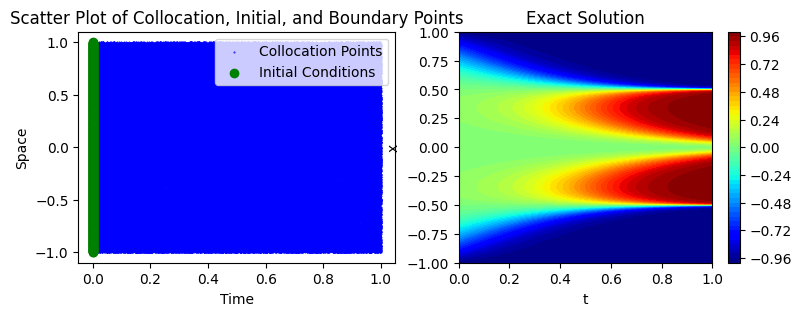

In [5]:
# Collocation points
lb_D = jnp.array([t0.min(), x0.min()])
ub_D = jnp.array([t0.max(), x0.max()])
# Generate collocation points and ensure they are float64
X_c = lb_D + (ub_D - lb_D) * lhs(2, NC)
X_c = X_c.astype(jnp.float64) 
tc = X_c[:, 0:1]
xc = X_c[:, 1:2]
# Initial conditions
ti = T[:, 0:1]
xi = X[:, 0:1]
ui = Exact0[:, 0:1]
# Boundary Conditions (not used in the 2nd order part, but good practice)
keys = jax.random.split(key, 13)
tb = jax.random.uniform(keys[3], (NB, 1), minval=lb_D[0], maxval=ub_D[0]).astype(jnp.float64)
# This data tuple is now consistently float64
train_data = tc, xc, ti, xi, ui
lambdas = tc * 0 + 0.1

# Plotting code
fig = plt.figure(figsize=(9, 3))
# Scatter plot for collocation, initial, and boundary points
ax1 = fig.add_subplot(121)
ax1.scatter(tc, xc, color='blue', label='Collocation Points',s=0.2)
ax1.scatter(ti, xi, color='green', label='Initial Conditions')
ax1.set_xlabel('Time')
ax1.set_ylabel('Space')
ax1.set_title('Scatter Plot of Collocation, Initial, and Boundary Points')
ax1.legend()

# Surface plot for Exact solution
ax2 = fig.add_subplot(122)
contour = ax2.contourf(T, X, Exact0, cmap='jet', levels=50)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_title('Exact Solution')
plt.savefig('Boundaries_data.png',dpi=300)
plt.show()

## Cell 5: Model Architecture Definition (The PINN Structure)

In [6]:
class Periodic_Fourier_Features(nn.Module):
    kmax: int = 1
    Lx: float = 2.0 
    @nn.compact
    def __call__(self, X: Array) -> Array:
        ks = jnp.arange(1, self.kmax + 1)
        Xper = 2 * jnp.pi * jnp.matmul(X, ks[None, :]) / self.Lx
        xcos = jnp.cos(Xper)
        xsin = jnp.sin(Xper)
        Xper = jnp.concatenate([xcos, xsin], axis=1)
        return Xper

class MLP(nn.Module):
    features: Sequence[int]
    activation: Callable = nn.tanh 
    
    @nn.compact
    def __call__(self, Z: Array) -> Array:
        init = nn.initializers.glorot_normal()
        for fs in self.features[:-1]:
            Z = nn.Dense(fs, kernel_init=init)(Z)
            # Use the activation function from the attribute
            Z = self.activation(Z) 
        Z = nn.Dense(self.features[-1], kernel_init=init)(Z)
        return Z

class PINN(nn.Module):
    features: Sequence[int]
    embedding_degree: int = 1   
    Lx: float = 2.0 
    activation: Callable = nn.tanh 

    def setup(self):
         self.enbedding = Periodic_Fourier_Features(kmax=self.embedding_degree, Lx=self.Lx)
         self.MLP = MLP(features=self.features, activation=self.activation)

    @nn.compact
    def __call__(self, t: Array, x: Array) -> Array:
        x_embedded = self.enbedding(x)
        X_concat = jnp.concatenate([t, x_embedded], axis=-1)
        H = self.MLP(X_concat)
        return H

## Cell 6: Model and Optimizer Initialization

In [7]:
feat_sizes = tuple([HIDDEN for _ in range(N_LAYERS)] + [FEATURES])
print(feat_sizes)
# make & init model
model = PINN(feat_sizes,activation=nn.tanh,embedding_degree=embedding_degree)
params = model.init(subkey, jnp.ones((NC, 1), dtype=jnp.float64), jnp.ones((NC, 1), dtype=jnp.float64))
params = jax.tree_util.tree_map(lambda x: x.astype(jnp.float64), params)
optimizers = {}
for key_params in params['params'].keys():
    if key_params=='g_fx':
        optimizers[key_params]=optax.adam(optax.exponential_decay(lr0*args.lr_fact, decay_step, decay_rate, staircase=False))
    else:
        optimizers[key_params]=optax.adam(optax.exponential_decay(lr0, decay_step, decay_rate, staircase=False))
# Initialize optimizer states for each parameter group
states = {key_params: optim.init(params['params'][key_params]) for key_params, optim in optimizers.items()}
# forward & loss function
apply_fn = jax.jit(model.apply)
total_params = sum(x.size for x in jax.tree_util.tree_leaves(params))
print(total_params )

(30, 30, 30, 1)
2011


## Cell 7: PDE Residual Definition

In [8]:
def Allen_Cahn(params, t, x, apply_fn):
    u = apply_fn(params, t, x)
    v_t = jnp.ones_like(t)
    v_x = jnp.ones_like(x)
    ut = jvp(lambda t_val: apply_fn(params, t_val, x), (t,), (v_t,))[1]
    uxx = hvp_fwdfwd(lambda x_val: apply_fn(params, t, x_val), (x,), (v_x,))
    return ut - 0.0001 * uxx + 5.0 * u ** 3 - 5.0 * u

PDE_residuals=Allen_Cahn

## Cell 9: vRBA Steps 1 & 3 - Weight & Multiplier Generation

In [9]:
def update_vRBA(
    r_i_norm, lambdas_batch, it,
    c_log=1.0, gamma=0.999, eta=0.01, phi=1.0,
    potential_type='exponential'):
    
    if potential_type == 'exponential':
        epsilon_q = c_log * jnp.max(r_i_norm) / jnp.log(it + 2.0)
        beta_it = 1.0 / (epsilon_q + 1e-20)
        q_it = beta_it * jnp.exp(beta_it * r_i_norm)
    elif potential_type == 'quadratic':# Standard RBA
        q_it = r_i_norm
    elif potential_type == 'linear': # No weights
        q_it = jnp.ones_like(r_i_norm)
    
    lambda_it = phi * q_it / (q_it.max() + 1e-20) + (1.0 - phi)
    new_lambdas = gamma * lambdas_batch + eta * lambda_it# EMA
    return new_lambdas

METHOD = 'exponential' 
c_log = 1.0 
phi = 1.0

update_fn_with_baked_in_type = partial(
    update_vRBA,
    c_log=c_log,
    phi=phi,
    potential_type=METHOD
)
update_weights_fn = jax.jit(update_fn_with_baked_in_type)

## Cell 10: Optax Model Update Step

In [10]:
@partial(jax.jit, static_argnums=(0, 1))  # key and optimizer are static
def update_model(key_params, optimizer, gradient, params, state):
    updates, new_state = optimizer.update(gradient['params'][key_params], state)
    new_params = optax.apply_updates(params['params'][key_params], updates)
    params['params'][key_params] = new_params
    return params, new_state


## Cell 11: Main Training Step (Adam) & Gradient Calculation

In [11]:
@partial(jax.jit, static_argnums=(0, 1))
def apply_model(
    apply_fn,
    update_weights_fn,     
    params, lambdas, lamB, 
    all_grads,  # 
    idx_train, it,
    hyperparams,    
    *train_data
):
    lamE,gamma, eta, gamma_grads, alpha = hyperparams
    t, x, ti, xi, ui = train_data
    lambdas_it = lambdas[idx_train]

    def loss_pde(params, lambdas):
        residuals = PDE_residuals(params, t, x, apply_fn) 
        r_i_norm = lax.stop_gradient(jnp.abs(residuals))
        new_lambdas = update_weights_fn(r_i_norm,lambdas, it, 
                                          gamma=gamma,
                                          eta=eta)
        pde_loss = jnp.mean((new_lambdas * residuals) ** 2)
        return pde_loss, new_lambdas

    def loss_bcs(params):
        u_pred = apply_fn(params, ti, xi)
        ics_loss = jnp.mean((ui - u_pred) ** 2)
        return ics_loss

    (pde_loss, new_lambdas), gradient_pde = jax.value_and_grad(loss_pde, has_aux=True)(params, lambdas_it)
    ics_loss, gradient_bcs = jax.value_and_grad(loss_bcs)(params)
    lambdas = lambdas.at[idx_train].set(new_lambdas)
    pde_gradient_flat, _ = ravel_pytree(gradient_pde)
    bcs_gradient_flat, _ = ravel_pytree(gradient_bcs)
    grad_PDE_norm = jnp.linalg.norm(pde_gradient_flat) + 1e-20
    grad_bcs_norm = jnp.linalg.norm(bcs_gradient_flat) + 1e-20
    
    # This line now correctly uses the 'all_grads' that was passed in
    grad_avg_PDE = gamma_grads * all_grads['grad_bar_PDE'] + (1.0 - gamma_grads) * grad_PDE_norm
    grad_avg_BCs = gamma_grads * all_grads['grad_bar_BCs'] + (1.0 - gamma_grads) * grad_bcs_norm
    
    lamB = alpha * lamB + (1.0 - alpha) * grad_avg_PDE / (grad_avg_BCs + 1e-20)
    total_gradient = jax.tree_util.tree_map(lambda g_pde, g_bcs: lamE * g_pde + lamB * g_bcs, gradient_pde, gradient_bcs)
    
    all_loss = {
        'loss_PDE': pde_loss,
        'loss_BCs': ics_loss,
        'Loss': lamE * pde_loss + lamB * ics_loss,
    }    
    all_grads_updated = {
        'grad_bar_PDE': grad_avg_PDE,
        'grad_bar_BCs': grad_avg_BCs,
    }
    
    return all_loss, total_gradient, lambdas, lamB, all_grads_updated


## Cell 12: vRBA Implementation via Importance Sampling


In [12]:
@partial(jax.jit, static_argnames=("batch_size", "k", "c"))
def sample_points_pdf(key, batch_size, lambdas, tc, xc, ti, xi, ui, k=1, c=0.5):
    # Adjust lambdas with exponent k and normalize
    lambdas_k = lambdas**k
    lambdas_k = lambdas_k / (lambdas_k.mean() + 1e-20) + c # Added epsilon
    lambdas_k = lambdas_k.flatten()
    p = lambdas_k / (lambdas_k.sum() + 1e-20) # Added epsilon
    idx_train = jax.random.choice(
        key, len(lambdas), shape=(batch_size,), p=p
    )
    train_data = (tc[idx_train], xc[idx_train], ti, xi, ui)
    return idx_train, train_data

## Cell 13: Main Adam Training Loop

In [13]:
def get_gamma(eta, max_RBA):
    gamma_it = 1-eta/max_RBA
    return gamma_it

In [14]:
all_errors = []
all_L_infty = []
all_L_2 = []
all_its = []
all_loss = []
all_gamma = []
all_lamB = []
all_max_RBA = []
all_lambdas=[]
all_idx=[]

start = time.time()
pbar = tqdm(range(1, EPOCHS + 1), desc='Training Progress')
gamma_it=get_gamma(eta, max_RBA0)
#Global weights
max_RBA=max_RBA0
lamE,lamB=1,max_RBA**2
#RBA
step_RBA=(cap_RBA-max_RBA0)/(EPOCHS/50000-1)
# initialize grads container
all_grads={
    'grad_bar_PDE':1,
    'grad_bar_BCs':1,
}
for e in pbar:
    key, subkey = jax.random.split(key)
    idx_train, train_data = sample_points_pdf(
        subkey, batch_size, lambdas, tc, xc, ti, xi, ui, k=args.k_samp, c=args.c_samp
    )
    # single run
    hyperparams = (lamE,gamma_it, eta, gamma_grads, alpha)
    all_loss_it, gradient, lambdas, lamB, all_grads = apply_model(
            apply_fn, update_weights_fn,
            params, lambdas,
            lamB,
            all_grads,
            idx_train,
            e,                
            hyperparams,  
            *train_data
        )

    for key_params in params['params']:
        params, states[key_params] = update_model(key_params, optimizers[key_params], gradient, params, states[key_params])
    log_frequency = 1 if e < 500 else 100 if e <= 5000 else 500
    if e % log_frequency == 0:
        # Update RBA
        max_RBA=max_RBA0+step_RBA*e//50000
        gamma_it=get_gamma(eta, max_RBA)
        all_lambdas.append(np.array(lambdas))  #
        all_idx.append(idx_train)
        #Compute errors
        u_pred_it=apply_fn(params, t, x)
        error = relative_l2(u_pred_it, u_gt)
        error_vec = u_pred_it - u_gt
        L_infty = scipy.linalg.norm(error_vec.flatten(), ord=np.inf)
        L_2 = scipy.linalg.norm(error_vec.flatten(), ord=2)
        # Updating the tqdm progress bar with loss and other metrics
        pbar.set_description(f"It: {e}/{EPOCHS} | Error: {error:.3e} | lam_max: {lambdas.max():.3f}| max_RBA: {max_RBA:.3f}| lamB: {lamB:.3f}|")
        all_errors.append(error)
        all_its.append(e)
        all_lambdas.append(np.array(lambdas))
        all_loss.append(all_loss_it['Loss'])
        all_gamma.append(gamma_it)
        all_lamB.append(lamB)
        all_max_RBA.append(max_RBA)
        # Error norms
        all_L_infty.append(L_infty)
        all_L_2.append(L_2)
end = time.time()
print(f'Runtime: {((end - start) / EPOCHS * 1000):.2f} ms/iter.')

It: 2500/2500 | Error: 1.058e+00 | lam_max: 1.840| max_RBA: 9.000| lamB: 100.000|: 100%|██████████| 2500/2500 [00:13<00:00, 190.88it/s]

Runtime: 5.24 ms/iter.


## Cell 14: Visualization & Evaluation (Adam Phase)


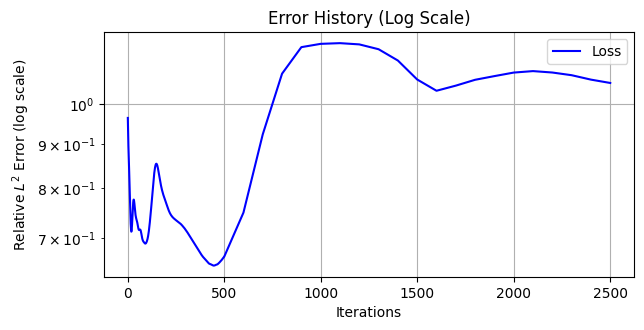

In [15]:
# Adjusting the plot to use a log scale for both loss and error
plt.figure(figsize=(12, 6))
# Plotting loss history with log scale
plt.subplot(2, 2, 1)
plt.plot(all_its, all_errors, label='Loss', color='blue')
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Relative $L^2$ Error (log scale)')
plt.title('Error History (Log Scale)')
plt.grid(True)
plt.legend()

# Show the plots
plt.tight_layout()
plt.savefig('Loss_Adam.png')
plt.show()


In [16]:
error = relative_l2(apply_fn(params, t, x), u_gt)
print(f'RL2 error: {error:.8f}') 

RL2 error: 1.05758095


Solution:


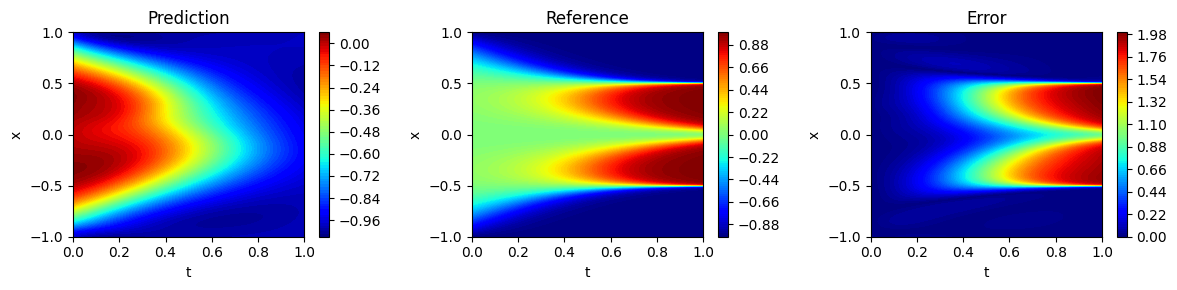

In [17]:
it=-1
print('Solution:')
u = apply_fn(params, t, x)
u = u.reshape(T.shape)
lambdas_grid=all_lambdas[it]
idx_it=all_idx[it]

# Plotting code
fig = plt.figure(figsize=(12, 3))
levels=100
# Scatter plot for collocation, initial, and boundary points
ax1 = fig.add_subplot(131)
contour = ax1.contourf(T, X, u, cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax1.set_xlabel('t')
ax1.set_ylabel('x')
ax1.set_title('Prediction')

# Surface plot for Exact solution
ax2 = fig.add_subplot(132)
contour = ax2.contourf(T, X, Exact0, cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_title('Reference')
# Surface plot for Exact solution
ax3 = fig.add_subplot(133)
contour = ax3.contourf(T, X, np.abs(Exact0-u), cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax3.set_xlabel('t')
ax3.set_ylabel('x')
ax3.set_title('Error')
plt.tight_layout()

plt.savefig('Errorss_Adam.png',dpi=300)
plt.show()


## Cell 15: Preparation for Second-Order Optimization (SSBroyden)

In [18]:
gamma = args.gamma_bfgs
eta = 1-gamma
initial_weights, unflatten_func = ravel_pytree(params)
params_test=unflatten_func(initial_weights)
error = relative_l2(apply_fn(params, t, x), u_gt)
print(f'RL2 error: {error:.8f}') 
error = relative_l2(apply_fn(params_test, t, x), u_gt)
print(f'Reconstructed parameters: RL2 error: {error:.8f}') 
X=np.hstack([tc.astype(jnp.float64),xc.astype(jnp.float64)])

RL2 error: 1.05758095
Reconstructed parameters: RL2 error: 1.05758095



## Cell 16: Defining the Loss Functions for Second-Order Optimization

In [19]:
@partial(jax.jit, static_argnums=(0,))
def apply_model_2nd_Order(apply_fn, params, *train_data):
    t, x, ti, xi, ui = train_data
    def loss_pde(params):
        # Compute residuals
        residuals = PDE_residuals(params, t, x, apply_fn)
        pde_loss = jnp.mean((residuals)**2)
        return pde_loss
    def loss_bcs(params):
        # Compute initial condition loss
        u_pred = apply_fn(params, ti, xi)
        ics_loss = jnp.mean((ui - u_pred) ** 2)
        return ics_loss
    def loss(params):
        return loss_pde(params)+10.0*loss_bcs(params)
    loss_value=loss(params)
    return loss_value

In [20]:
@partial(jax.jit, static_argnums=(0,))
def update_lambdas(apply_fn,params,lambdas,gamma,eta,tc,xc,it):
    t,x=tc,xc
    def get_lambdas(params, lambdas):
        residuals = PDE_residuals(params, t, x, apply_fn)
        # Update lambdas
        r_i_norm = lax.stop_gradient(jnp.abs(residuals))
        new_lambdas = update_weights_fn(r_i_norm,lambdas, it, 
                                          gamma=gamma,
                                          eta=eta)
        return new_lambdas
    new_lambdas=get_lambdas(params, lambdas)
    return new_lambdas

In [21]:
@partial(jax.jit, static_argnums=(1, 2))
def loss_and_gradient(weights, N_arg, unflatten_func_arg, *train_data_tuple_arg):
    flat_jax_array = weights 
    params_current = unflatten_func_arg(flat_jax_array)
    loss_val_jax = apply_model_2nd_Order(N_arg, params_current, *train_data_tuple_arg)
    return loss_val_jax


## Cell 17: The SSBroyden Optimization Step Function

In [22]:

@partial(jax.jit, static_argnames=("apply_fn", "unflatten_func", "batch_size", "gamma", "eta", "k", "c", "static_options"))
def SSBroyden_step(
    initial_weights, H0, key,
    tc, xc, lambdas,
    apply_fn, unflatten_func, batch_size, gamma, eta, k, c, static_options,it,
    ti, xi, ui ):
    key, subkey = jax.random.split(key)
    # 2. Update Lambdas ...
    params_it = unflatten_func(initial_weights)
    updated_lambdas = update_lambdas(apply_fn, params_it, lambdas, gamma, eta, tc, xc,it)
    _ , current_train_data_tuple = sample_points_pdf(
        subkey, batch_size, updated_lambdas, tc, xc, ti, xi, ui, k, c
    )
    # 4. Prepare the full options dictionary for minimize
    current_options = dict(static_options)
    current_options['initial_H'] = H0
    # 5. Run the SSBroyden optimization for Nchange steps
    result = minimize(
        fun=loss_and_gradient,
        x0=initial_weights,
        args=(apply_fn, unflatten_func, *current_train_data_tuple),
        method='BFGS', # SSBroyden version of BFGs
        options=current_options)
    # 6. Recycle the Hessian purely
    new_H0 = result.hess_inv
    new_H0 = (new_H0 + jnp.transpose(new_H0)) / 2
    try:
        L = jnp.linalg.cholesky(new_H0)
        is_failed = jnp.any(jnp.isnan(L))
        final_H0 = jax.lax.cond(
            is_failed,
            lambda op: jnp.eye(op.shape[0], dtype=op.dtype),
            lambda op: op,
            operand=new_H0)
    except LinAlgError:
        final_H0 = jnp.eye(new_H0.shape[0], dtype=new_H0.dtype)
    return result.x, final_H0, key, result.fun, result.nit, updated_lambdas

## Cell 18: Main SSBroyden Training Loop

In [23]:
# Initialize the Hessian
H0 = jnp.eye(len(initial_weights), dtype=jnp.float64)
num_outer_iterations = Nbfgs // Nchange
## SSBroyden Hyperparameters
static_options = static_options_SSBroyden
static_options['maxiter']=Nchange
static_options_tuple = tuple(static_options.items())
# Training
pbar = tqdm(range(num_outer_iterations), desc="SSBroyden Training")
effective_steps=0
Adam_Steps=all_its[-1]
for it in pbar:
    initial_weights, H0, key, loss_val, nit, lambdas = SSBroyden_step(
        initial_weights, H0, key,
        tc, xc, lambdas,
        apply_fn, unflatten_func, batch_size, gamma, eta, k_samp_bfgs, c_samp_bfgs,
        static_options_tuple,it,
        ti, xi, ui
    )
    effective_steps=effective_steps+nit
    current_params_for_eval = unflatten_func(initial_weights)
    u_pred_it=apply_fn(current_params_for_eval, t, x)
    error = relative_l2(u_pred_it, u_gt)
    error_vec = u_pred_it - u_gt
    L_infty = scipy.linalg.norm(error_vec.flatten(), ord=np.inf)
    L_2 = scipy.linalg.norm(error_vec.flatten(), ord=2)
    all_errors.append(error)
    all_loss.append(loss_val)
    all_its.append(effective_steps+Adam_Steps)
    all_L_infty.append(L_infty)
    all_L_2.append(L_2)
    pbar.set_postfix({
        'It': effective_steps,
        'Loss': f'{loss_val:.3e}',
        'RL2': f'{float(error):.3e}',
        'lam_min': f'{jnp.min(lambdas):.3e}',
        'lam_max': f'{jnp.max(lambdas):.3e}',
    }) 

SSBroyden Training: 100%|██████████| 125/125 [00:26<00:00,  4.76it/s, It=8704, Loss=3.826e-10, RL2=3.476e-05, lam_min=7.944e-03, lam_max=9.032e-01]



## Cell 19: Final Visualization & Error Reporting

In [25]:
T, X = np.meshgrid(t0, x0)
# Ground Truth (already float64 due to T, X)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]
it=-1
print('Solution:')
u = apply_fn(current_params_for_eval, t, x)
u = u.reshape(T.shape)

Solution:


Calculating PDE residuals for plotting...
Residuals calculated. Min: 4.0258463229747576e-11, Max: 0.03139575149401441


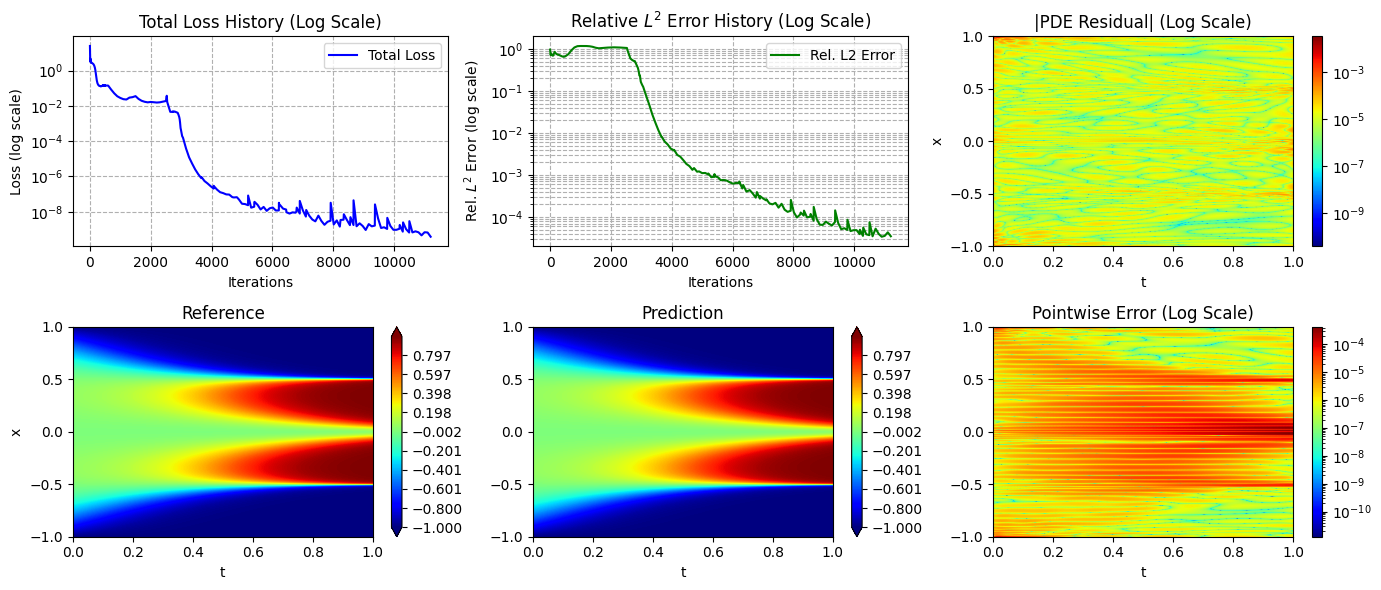

Minimum achieved  RL2 error: 3.390950828070826e-05


In [28]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
ax_tl = axes[0, 0]
ax_tl.plot(all_its, all_loss, label='Total Loss', color='blue')
ax_tl.set_yscale('log')
ax_tl.set_title('Total Loss History (Log Scale)')
ax_tl.set_xlabel('Iterations')
ax_tl.set_ylabel('Loss (log scale)')
ax_tl.grid(True, which="both", ls="--")
ax_tl.legend()
ax_tm = axes[0, 1]
ax_tm.plot(all_its, all_errors, label='Rel. L2 Error', color='green')
ax_tm.set_yscale('log')
ax_tm.set_title('Relative $L^2$ Error History (Log Scale)')
ax_tm.set_xlabel('Iterations')
ax_tm.set_ylabel('Rel. $L^2$ Error (log scale)')
ax_tm.grid(True, which="both", ls="--")
ax_tm.legend()
ax_tr = axes[0, 2]
print("Calculating PDE residuals for plotting...")
res = PDE_residuals(current_params_for_eval, t, x, apply_fn)
res_grid = jnp.abs(res.reshape(T.shape))
print(f"Residuals calculated. Min: {res_grid.min()}, Max: {res_grid.max()}")
res_log_norm = colors.LogNorm(vmin=res_grid.min()+1e-16, vmax=res_grid.max() + 1e-16)
mesh_res = ax_tr.pcolormesh(T, X, res_grid, cmap='jet', norm=res_log_norm, shading='gouraud')
fig.colorbar(mesh_res, ax=ax_tr)
ax_tr.set_xlabel('t')
ax_tr.set_ylabel('x')
ax_tr.set_title('|PDE Residual| (Log Scale)')
global_vmin = np.min([u, Exact0])
global_vmax = np.max([u, Exact0])
shared_levels = np.linspace(global_vmin, global_vmax, 500)
ax_bl = axes[1, 0]
contour1 = ax_bl.contourf(T, X, Exact0, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour1, ax=ax_bl)
ax_bl.set_xlabel('t')
ax_bl.set_ylabel('x')
ax_bl.set_title('Reference')
ax_bm = axes[1, 1]
contour2 = ax_bm.contourf(T, X, u, cmap='jet', levels=shared_levels, extend='both')
fig.colorbar(contour2, ax=ax_bm)
ax_bm.set_xlabel('t')
ax_bm.set_title('Prediction')
ax_br = axes[1, 2]
error_data = np.abs(Exact0 - u)
err_log_norm = colors.LogNorm(vmin=error_data.min()+1e-16, vmax=error_data.max() + 1e-16)
mesh_err = ax_br.pcolormesh(T, X, error_data, cmap='jet', norm=err_log_norm, shading='gouraud')
fig.colorbar(mesh_err, ax=ax_br)
ax_br.set_xlabel('t')
ax_br.set_title('Pointwise Error (Log Scale)')
plt.tight_layout()
plt.savefig('summary_all.png', dpi=150) # 150 DPI is a good balance for token size
plt.show()
print('Minimum achieved  RL2 error:',np.nanmin(all_errors))

## Cell 20: Save Experiment Results to .mat File


In [29]:
results_dict = {
    'model_name': args.Name,
    'all_errors': all_errors,
    'all_its': all_its,
    'all_loss': all_loss,
    'all_gamma': all_gamma,
    'all_lamB': all_lamB,
    'all_max_RBA': all_max_RBA,
    'all_L_infty':all_L_infty,
    'all_L_2':all_L_2,
}
# Save dictionary as a .mat file
scipy.io.savemat('Log_files_SSBroyden.mat', results_dict)